# 06 — Overview: substantive speech, politicians over time, polarizing topics

**Preliminary — for discussion, not citation.**

The `d100k` run (`20261018T122536Z`; S19, P8): 99,996 floor speeches, 1,923 per
Congress × party × chamber, 2001–2025, scored by DeepSeek-V4.1-Flash-1017 alone, each
labelled with a speech type and, for policy debate, a topic (L1–L8).

This notebook asks three things:

1. **The overview on substantive speech.** Procedural and ceremonial speeches are
   left out **by their label** (A3, settling O12 for this analysis): they carry no
   position, and with one model the "scored 0.0" proxy would also drop a fifth of the
   policy debates (P8). Bill introductions, constituent items and "other" stay in.
2. **Politicians over time.** Members followed across Congresses, against their
   party and against their own voting record (Nokken-Poole).
3. **Which topics polarized.** The party gap per topic block and Congress, and the
   change per topic over 2001–2025.
4. **Age, generation and tenure.** Are younger or newer members further out, or
   harsher in tone, than their colleagues in the same party, chamber and Congress?

Rules as before: **House and Senate apart**, **intervals clustered by member**, the
**2016-09-10 source break** marked. Logic in `code/src/analysis.py` and `plots.py`
(tested). Figures to `results/plots/overview_*`, tables to `results/metrics/overview_*`.
No API calls.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT / "code"))

import matplotlib.pyplot as plt
import pandas as pd

from src.analysis import (
    AGE_GROUPS, GENERATION_ORDER, TENURE_GROUPS, add_background, attach_labels,
    cell_means, gap_trend, load_scored_run, member_background, member_trajectories,
    member_trends, party_gap, relative_to_cell, substantive, toward_party, trend,
    within_cell_ols,
)
from src.config import EXCLUDED_SPEECH_TYPES, METRICS_DIR, TOPIC_BLOCKS
from src.label_eval import label_shares
from src.labeling import BLOCK_OF_TOPIC
from src.plots import (
    TOPIC_BLOCK_PALETTE, plot_gap, plot_gap_by_group, plot_gap_trends,
    plot_group_means, plot_label_shares, plot_member_slopes,
    plot_member_trajectories, plot_party_positions, save_figure,
)

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 60)

RUN = "20261018T122536Z"        # d100k (S19)
LABEL_RUN = "20261017T182223Z"  # speech type and topic (L1-L8)

everything = attach_labels(load_scored_run(RUN), LABEL_RUN).dropna(subset=["ideology"])
df = substantive(everything)
print(f"{len(df):,} of {len(everything):,} scored speeches kept; left out: "
      f"{', '.join(EXCLUDED_SPEECH_TYPES)} and the unlabelled")

71,121 of 99,993 scored speeches kept; left out: procedural, ceremonial and the unlabelled


In [2]:
def with_ci(table, value="mean", digits=2):
    """'0.46 [0.35, 0.57]' -- a value with its 95% interval."""
    return table.apply(
        lambda r: f"{r[value]:+.{digits}f} [{r['ci_low']:+.{digits}f}, {r['ci_high']:+.{digits}f}]",
        axis=1,
    )


def span_ci(table, digits=2):
    """The change over the span with its interval: the slope's, times the span."""
    span = table["span"].map(lambda s: int(s.split("-")[1]) - int(s.split("-")[0]))
    return table.assign(ci_low=table["ci_low"] * span, ci_high=table["ci_high"] * span).pipe(
        with_ci, "change_over_span", digits
    )

## 1. What is left out

Procedural and ceremonial speeches are not spread evenly: the Senate holds more
procedural business, and House ceremonial speeches rise after 2016 (L7). Leaving them
out therefore changes the mix per chamber and period — which is the point: it removes
a composition shift that is not about positions.

In [3]:
dropped = 1 - df.groupby(["congress_number", "chamber"]).size() / everything.groupby(["congress_number", "chamber"]).size()
print("Share of speeches left out (%), per Congress and chamber:")
(dropped.unstack("chamber") * 100).round(1).T

Share of speeches left out (%), per Congress and chamber:


congress_number,107,108,109,110,111,112,113,114,115,116,117,118,119
chamber,,,,,,,,,,,,,
H,23.5,22.2,20.8,22.5,21.5,18.3,18.8,22.5,24.4,26.8,25.0,27.5,31.8
S,33.3,34.1,36.1,35.5,31.7,35.9,35.5,35.6,30.8,32.0,34.3,37.5,32.8


In [4]:
gap_all = party_gap(cell_means(everything))
gaps = party_gap(cell_means(df))
print("Party gap (R − D): all speeches vs substantive speeches")
pd.concat({
    "all speeches": gap_all.pivot(index="congress_number", columns="chamber", values="gap").round(2),
    "substantive": gaps.pivot(index="congress_number", columns="chamber", values="gap").round(2),
}, axis=1).T

Party gap (R − D): all speeches vs substantive speeches


congress_number        107   108   109   110   111   112   113   114   115  \
             chamber                                                         
all speeches H        0.42  0.51  0.52  0.54  0.70  0.78  0.68  0.60  0.63   
             S        0.31  0.34  0.37  0.39  0.58  0.53  0.53  0.52  0.71   
substantive  H        0.52  0.62  0.62  0.66  0.85  0.93  0.81  0.74  0.79   
             S        0.45  0.48  0.54  0.58  0.81  0.78  0.77  0.76  0.94   

congress_number        116   117   118   119  
             chamber                          
all speeches H        0.57  0.76  0.72  0.75  
             S        0.63  0.69  0.61  0.75  
substantive  H        0.72  0.97  0.94  1.03  
             S        0.85  0.98  0.90  1.06

**Reading it.** Leaving out procedural and ceremonial speeches removes 18–24% of
House speeches up to 2016, rising to 32% in 2025 as ceremonial speeches grow, and
31–38% of Senate speeches throughout. The gap on what remains is larger in every
Congress, because the left-out speeches sit near 0.0 for both parties. **The
difference grows over time** (House 0.10 → 0.28, Senate 0.14 → 0.31), so gaps
over all speeches *understate* how much the parties drew apart.

## 2. The overview: how far apart, and who moved

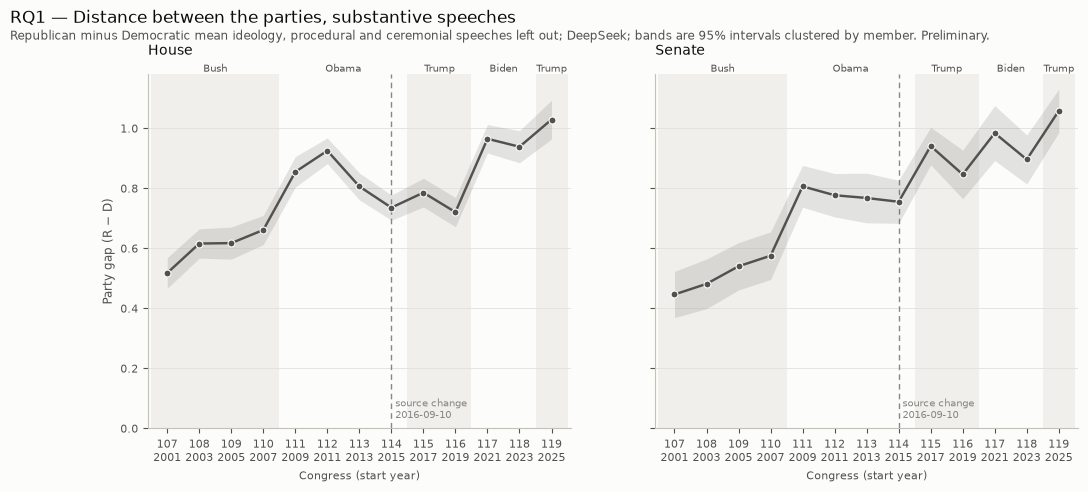

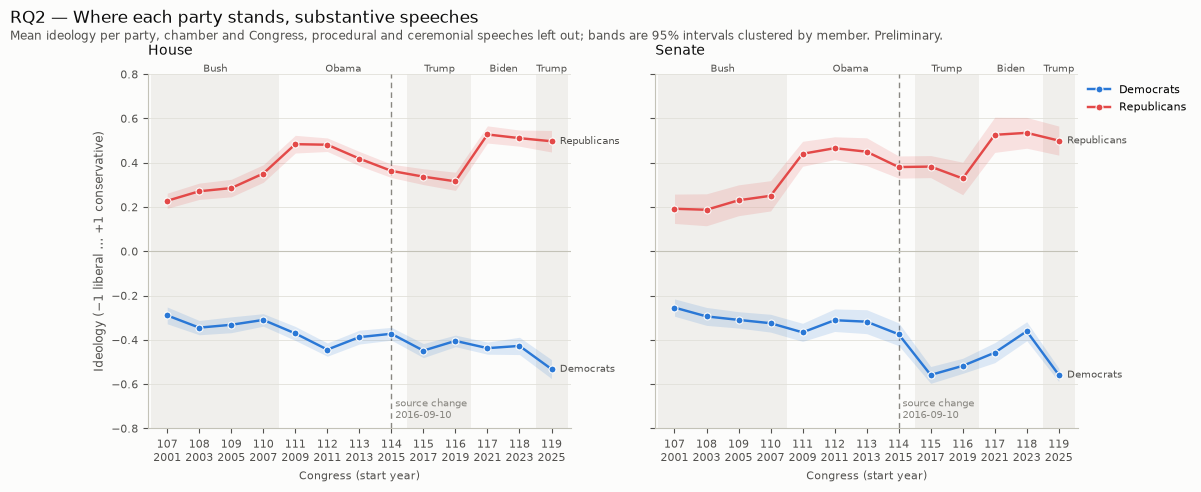

In [5]:
fig = plot_gap(
    gaps,
    "RQ1 — Distance between the parties, substantive speeches",
    subtitle="Republican minus Democratic mean ideology, procedural and ceremonial speeches left out; DeepSeek; bands are 95% intervals clustered by member. Preliminary.",
)
save_figure(fig, "overview_party_gap")
plt.show()

cells = cell_means(df)
fig = plot_party_positions(
    cells,
    "Ideology (−1 liberal … +1 conservative)",
    "RQ2 — Where each party stands, substantive speeches",
    subtitle="Mean ideology per party, chamber and Congress, procedural and ceremonial speeches left out; bands are 95% intervals clustered by member. Preliminary.",
    ylim=(-0.8, 0.8),
)
save_figure(fig, "overview_party_positions")
plt.show()

In [6]:
windows = {"2001–2016, Stanford only": (107, 114), "2001–2025, both sources": None}
gap_trends = pd.concat([gap_trend(df, congress_range=r).assign(window=w) for w, r in windows.items()])
party_trends = pd.concat([trend(df, congress_range=r).assign(window=w) for w, r in windows.items()])
print("Change in the party gap, first to last Congress (95% interval):")
display(gap_trends.assign(
    gap_first=gap_trends["gap_first"].round(2), change=span_ci(gap_trends),
    p=gap_trends["p"].map(lambda p: f"{p:.2g}"),
)[["window", "chamber", "span", "gap_first", "change", "p", "n"]].reset_index(drop=True))
print("Change in each party's position, first to last Congress (95% interval):")
party_trends.assign(change=span_ci(party_trends), p=party_trends["p"].map(lambda p: f"{p:.2g}"))[
    ["window", "chamber", "party", "span", "change", "p", "n", "n_members"]
].reset_index(drop=True)

Change in the party gap, first to last Congress (95% interval):


,window,chamber,span,gap_first,change,p,n
0,"2001–2016, Stanford only",H,107-114,0.57,"+0.30 [+0.24, +0.36]",4.2e-22,24223
1,"2001–2016, Stanford only",S,107-114,0.46,"+0.39 [+0.28, +0.50]",5.4e-13,20088
2,"2001–2025, both sources",H,107-119,0.59,"+0.39 [+0.32, +0.46]",1.1e-28,38242
3,"2001–2025, both sources",S,107-119,0.48,"+0.58 [+0.47, +0.70]",1.7e-23,32879


Change in each party's position, first to last Congress (95% interval):


,window,chamber,party,span,change,p,n,n_members
0,"2001–2016, Stanford only",H,D,107-114,"-0.10 [-0.14, -0.06]",1.1e-06,12443,404
1,"2001–2016, Stanford only",H,R,107-114,"+0.20 [+0.16, +0.25]",1.1e-17,11780,497
2,"2001–2016, Stanford only",S,D,107-114,"-0.09 [-0.14, -0.03]",0.0038,9924,97
3,"2001–2016, Stanford only",S,R,107-114,"+0.31 [+0.22, +0.39]",1.4e-11,10164,103
4,"2001–2025, both sources",H,D,107-119,"-0.17 [-0.22, -0.13]",6.9e-15,19929,580
5,"2001–2025, both sources",H,R,107-119,"+0.22 [+0.16, +0.27]",1.6e-15,18313,695
6,"2001–2025, both sources",S,D,107-119,"-0.26 [-0.32, -0.20]",3.6e-18,16792,123
7,"2001–2025, both sources",S,R,107-119,"+0.32 [+0.22, +0.42]",1.1e-10,16087,132


**Reading it.** On substantive speech **the gap roughly doubles**: House 0.52 in the
107th → 1.03 in the 119th, Senate 0.45 → 1.06. The fitted change is +0.30 [0.24, 0.36]
(House) and +0.39 [0.28, 0.50] (Senate) within 2001–2016 alone, and +0.39 / +0.58 over
2001–2025. **Both parties moved outward, Republicans further:** in 2001–2016
Republicans +0.20 (House) and +0.31 (Senate), Democrats −0.10 and −0.09. Over
2001–2025 Republicans +0.22 / +0.32 and Democrats −0.17 / −0.26: after 2016 the
Democratic move catches up, above all in the Senate. As in notebook 05, positions
also swing with the presidency (each party furthest out in opposition).

## 3. Politicians over time

A member's speeches in one Congress give their position that Congress. Members are
followed by their career-long ICPSR, in every Congress where they have **at least 10
substantive speeches** in the sample. Because the sample balances cells, not members,
frequent speakers — above all senators and party leaders — are the ones that can be
followed.

656 members have ≥ 10 speeches in at least one Congress; 170 in ≥ 5 Congresses, 63 in ≥ 8.


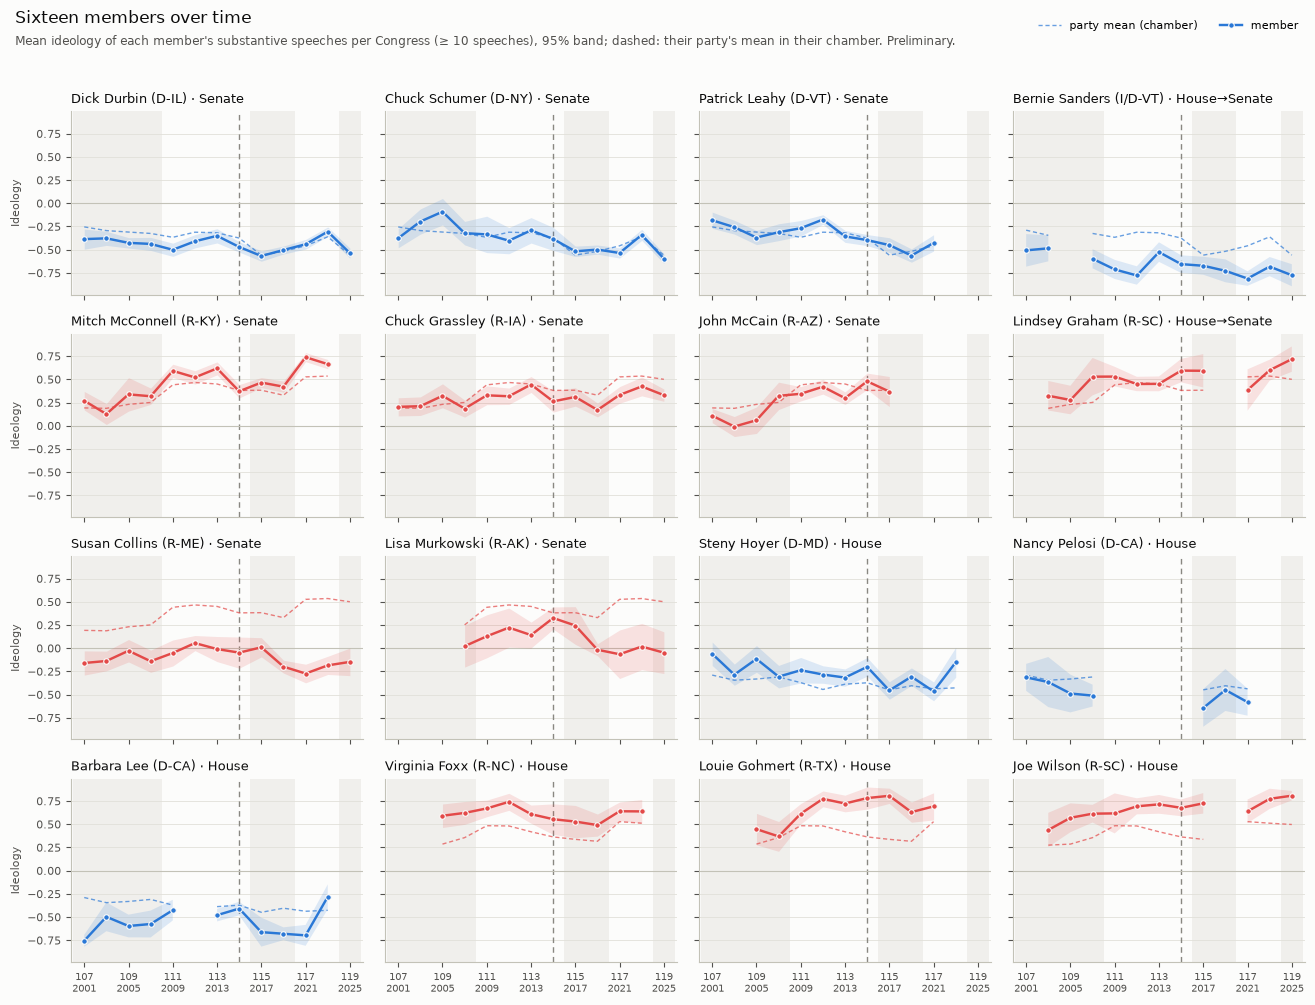

In [7]:
trajectories = member_trajectories(df, min_speeches=10)
followed = trajectories.groupby(["icpsr", "party"])["congress_number"].nunique()
print(f"{trajectories['icpsr'].nunique():,} members have ≥ 10 speeches in at least one Congress; "
      f"{(followed >= 5).sum()} in ≥ 5 Congresses, {(followed >= 8).sum()} in ≥ 8.")

# Chosen for coverage (≥ 10 speeches in many Congresses) and for range: leaders,
# moderates, firebrands, chamber switchers. Keyed on ICPSR, not on names.
FEATURED = {
    15021: "Dick Durbin (D-IL) · Senate",
    14858: "Chuck Schumer (D-NY) · Senate",
    14307: "Patrick Leahy (D-VT) · Senate",
    29147: "Bernie Sanders (I/D-VT) · House→Senate",
    14921: "Mitch McConnell (R-KY) · Senate",
    14226: "Chuck Grassley (R-IA) · Senate",
    15039: "John McCain (R-AZ) · Senate",
    29566: "Lindsey Graham (R-SC) · House→Senate",
    49703: "Susan Collins (R-ME) · Senate",
    40300: "Lisa Murkowski (R-AK) · Senate",
    14873: "Steny Hoyer (D-MD) · House",
    15448: "Nancy Pelosi (D-CA) · House",
    29778: "Barbara Lee (D-CA) · House",
    20521: "Virginia Foxx (R-NC) · House",
    20527: "Louie Gohmert (R-TX) · House",
    20138: "Joe Wilson (R-SC) · House",
}
fig = plot_member_trajectories(
    trajectories, FEATURED,
    "Sixteen members over time",
    subtitle="Mean ideology of each member's substantive speeches per Congress (≥ 10 speeches), 95% band; dashed: their party's mean in their chamber. Preliminary.",
)
save_figure(fig, "overview_member_trajectories")
plt.show()

**Reading it.** Many long-serving members track their party: **Durbin, Schumer,
Leahy, Hoyer and Grassley** stay close to the dashed party line and move as it moves.
Others hold a steady place inside their party: **Sanders** sits left of Senate Democrats
in every Congress (−0.5 to −0.8), **Collins** well left of Senate Republicans (−0.27 to
+0.05, against a party at +0.2 to +0.5), and the House Republicans **Foxx, Gohmert and
Wilson** right of theirs. Some move: **McConnell** from +0.1–0.3 (2001–2008) to
+0.66–0.74 (2021–2024); **McCain** from about 0 (2001–2006) to +0.3–0.5; **Graham**
drifts right with his party and ends beyond it (+0.72 in 2025); **Murkowski** moves
right with her party until 2016, then back to about 0 while it moves further right.
**Barbara Lee** moves around her party's line: furthest left in 2001 and again in
2017–2022, closest to it in 2023. Each point rests on 10 to about 200 speeches; the
bands show it.

**Who moved?** Each member's linear trend over the Congresses where they are
followed (≥ 10 speeches in ≥ 5 Congresses). `change` is the fitted change from their
first to their last such Congress; `vs party` the trend of their distance from their
party's mean (≈ 0: they moved as their party did); `votes` the slope of their
Nokken-Poole score per Congress.

In [8]:
movers = member_trends(df, min_speeches=10, min_congresses=5)
show = movers.assign(
    change=span_ci(movers),
    p=movers["p"].map(lambda p: f"{p:.2g}"),
    vs_party=(movers["slope_relative"]).round(3),
    votes=movers["slope_nokken_poole"].round(3),
    name=movers["bioname"].str.title(),
)[["name", "party", "chambers", "span", "congresses", "n", "change", "p", "vs_party", "votes"]]
order = movers["change_over_span"].sort_values().index
print(f"{len(movers)} members ({(movers['party'] == 'D').sum()} D, {(movers['party'] == 'R').sum()} R). Moved furthest left:")
display(show.loc[order[:8]].reset_index(drop=True))
print("Moved furthest right:")
show.loc[order[::-1][:8]].reset_index(drop=True)

170 members (96 D, 74 R). Moved furthest left:


,name,party,chambers,span,congresses,n,change,p,vs_party,votes
0,"Woodall, Rob",R,H,112-116,5,81,"-0.52 [-0.68, -0.36]",1.4e-10,-0.087,-0.051
1,"Roe, David P. (Phil)",R,H,111-116,5,111,"-0.51 [-0.66, -0.36]",4.7e-11,-0.065,-0.005
2,"Wyden, Ronald Lee",D,S,107-119,13,520,"-0.43 [-0.54, -0.33]",6.6e-16,-0.013,-0.010
3,"Casey, Robert (Bob), Jr.",D,S,110-117,7,153,"-0.37 [-0.50, -0.23]",1.6e-07,-0.023,-0.001
4,"Rubio, Marco",R,S,112-117,6,112,"-0.37 [-0.58, -0.16]",0.00065,-0.070,-0.001
5,"Udall, Thomas (Tom)",D,S,112-116,5,97,"-0.35 [-0.53, -0.18]",6.3e-05,-0.028,-0.004
6,"Carper, Thomas Richard",D,S,108-118,8,164,"-0.34 [-0.49, -0.19]",1.1e-05,-0.016,-0.009
7,"Thompson, Glenn",R,H,111-119,8,118,"-0.30 [-0.51, -0.09]",0.0057,-0.039,0.006


Moved furthest right:


,name,party,chambers,span,congresses,n,change,p,vs_party,votes
0,"Capito, Shelley Moore",R,HS,110-119,7,113,"+0.70 [+0.51, +0.88]",1.5e-13,0.054,0.013
1,"Enzi, Michael B.",R,S,107-115,9,250,"+0.51 [+0.37, +0.66]",5.3e-12,0.030,0.000
2,"Mccain, John Sidney, Iii",R,S,107-115,9,504,"+0.44 [+0.34, +0.55]",1.5e-17,0.015,0.025
3,"Gingrey, Phil",R,H,108-112,5,146,"+0.41 [+0.22, +0.59]",1.1e-05,0.033,0.020
4,"Schweikert, David",R,H,114-119,5,67,"+0.38 [+0.19, +0.57]",7.1e-05,0.040,-0.023
5,"Chambliss, Saxby",R,S,108-112,5,104,"+0.35 [+0.16, +0.54]",0.00032,0.007,0.010
6,"Mcconnell, Addison Mitchell (Mitch)",R,S,107-118,12,1085,"+0.34 [+0.27, +0.42]",1.9e-19,0.008,-0.007
7,"Sessions, Jefferson Beauregard (Jeff), Iii",R,S,107-114,8,487,"+0.30 [+0.19, +0.41]",8.6e-08,-0.010,0.013


,members,median slope per Congress,moved outward (p < 0.05),moved inward (p < 0.05),median slope vs own party,median Nokken-Poole slope
party,,,,,,
D,96.0,-0.009,0.302,0.042,0.007,0.001
R,74.0,0.012,0.338,0.122,-0.010,-0.003


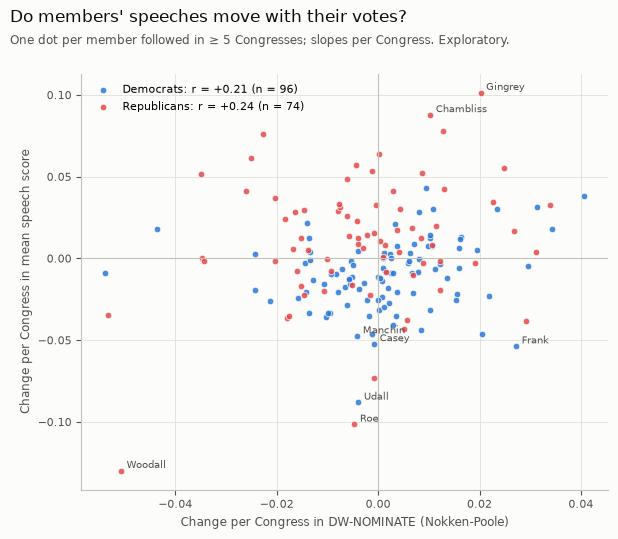

In [9]:
outward = movers.assign(direction=movers["party"].map({"D": -1, "R": 1}))
summary = outward.groupby("party").apply(lambda d: pd.Series({
    "members": len(d),
    "median slope per Congress": d["slope"].median(),
    "moved outward (p < 0.05)": ((d["slope"] * d["direction"] > 0) & (d["p"] < 0.05)).mean(),
    "moved inward (p < 0.05)": ((d["slope"] * d["direction"] < 0) & (d["p"] < 0.05)).mean(),
    "median slope vs own party": d["slope_relative"].median(),
    "median Nokken-Poole slope": d["slope_nokken_poole"].median(),
}), include_groups=False)
display(summary.round(3))

fig = plot_member_slopes(
    movers,
    "Do members' speeches move with their votes?",
    subtitle="One dot per member followed in ≥ 5 Congresses; slopes per Congress. Exploratory.",
)
save_figure(fig, "overview_member_slopes")
plt.show()

**Reading it.** Of the 170 members followed in at least five Congresses, about a
third moved outward significantly (30% of Democrats, 34% of Republicans); few moved
inward (4% of Democrats, 12% of Republicans). The largest moves right are Republican
senators — Capito (+0.70, House then Senate), Enzi, McCain, McConnell (+0.34 over 12
Congresses); the largest moves left are Democratic senators — Wyden (−0.43 over 13
Congresses), Casey, Udall, Carper. The Republicans who moved toward the centre
(Woodall, Roe, Rubio, Glenn Thompson) are followed for 5–8 Congresses only.

**Members moved less than their parties.** The median member drifts outward (Democrats
−0.009, Republicans +0.012 per Congress) but toward the centre *relative to their own
party* (+0.007, −0.010). The parties moved further than their sitting members did,
which points to **replacement** — newer members arriving further out — alongside
**conversion** of those who stay. Suggestive only: frequent speakers are not a random
set of members, and a member's own speeches are part of their party's mean.

**Speeches and votes move only loosely together:** a member's speech trend correlates
with their Nokken-Poole trend at r = 0.21 (D) and 0.24 (R), and voting scores barely
move within a career (median slope ≈ 0). Speech captures movement the roll-call record
does not show — or noise the averaging has not removed; this run cannot tell which.

## 4. Which topics polarized?

Policy debates only (a topic exists only there). First the gap per topic block and
Congress, then each of the 11 topics' change over 2001–2025. Single topics are too
thin for a line per Congress (education has as few as 6 speeches in a party cell), so
they get one trend each.

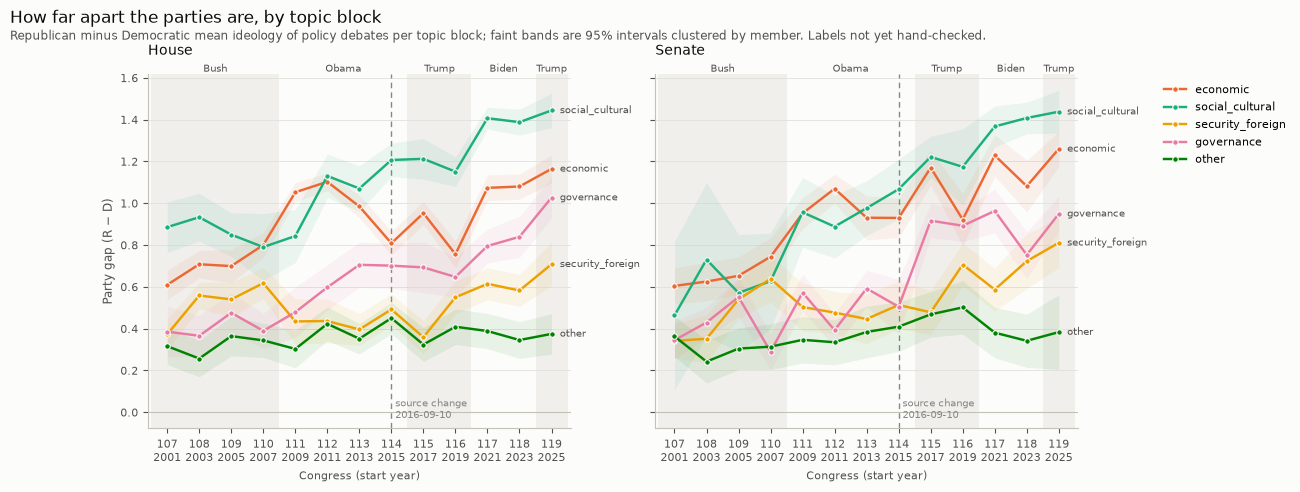

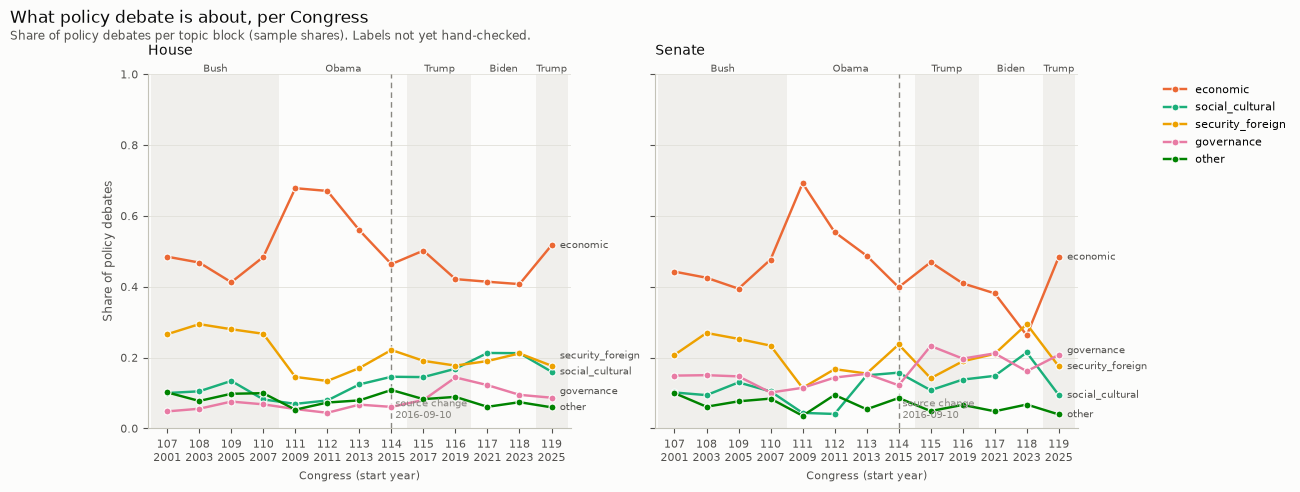

In [10]:
policy = df[df["speech_type"] == "policy_debate"]
blocks = list(TOPIC_BLOCKS)
block_gaps = party_gap(
    cell_means(policy, by=("congress_number", "chamber", "topic_block", "party")),
    by=("congress_number", "chamber", "topic_block"),
)
fig = plot_gap_by_group(
    block_gaps, "topic_block",
    "How far apart the parties are, by topic block",
    subtitle="Republican minus Democratic mean ideology of policy debates per topic block; faint bands are 95% intervals clustered by member. Labels not yet hand-checked.",
    order=blocks,
)
save_figure(fig, "overview_gap_by_topic_block")
plt.show()

block_shares = label_shares(policy, ["congress_number", "chamber"], column="topic_block")
fig = plot_label_shares(
    block_shares, "What policy debate is about, per Congress",
    subtitle="Share of policy debates per topic block (sample shares). Labels not yet hand-checked.",
    order=tuple(blocks), column="topic_block", palette=TOPIC_BLOCK_PALETTE,
    ylabel="Share of policy debates",
)
save_figure(fig, "overview_topic_block_shares")
plt.show()

In [11]:
block_trends = pd.concat([
    gap_trend(policy, by=("chamber", "topic_block"), congress_range=r).assign(window=w)
    for w, r in windows.items()
])
block_trends.assign(gap_first=block_trends["gap_first"].round(2), change=span_ci(block_trends),
                    p=block_trends["p"].map(lambda p: f"{p:.2g}")).pivot(
    index=["chamber", "topic_block"], columns="window", values="change"
)

window                   2001–2016, Stanford only 2001–2025, both sources
chamber topic_block                                                      
H       economic             +0.38 [+0.30, +0.46]    +0.38 [+0.30, +0.46]
        governance           +0.37 [+0.25, +0.49]    +0.57 [+0.47, +0.67]
        other                +0.13 [+0.03, +0.22]    +0.08 [-0.01, +0.17]
        security_foreign     -0.02 [-0.12, +0.07]    +0.11 [+0.01, +0.20]
        social_cultural      +0.34 [+0.21, +0.47]    +0.66 [+0.55, +0.76]
S       economic             +0.47 [+0.35, +0.59]    +0.63 [+0.51, +0.75]
        governance           +0.16 [+0.04, +0.28]    +0.67 [+0.55, +0.78]
        other                +0.07 [-0.06, +0.20]    +0.11 [-0.02, +0.24]
        security_foreign     +0.12 [-0.02, +0.26]    +0.34 [+0.20, +0.48]
        social_cultural      +0.60 [+0.18, +1.01]    +1.00 [+0.64, +1.35]

**Reading it.** The blocks start apart and drift apart at different speeds.
**Social-cultural issues are the most divided block and widened most** (fitted change
over 2001–2025: House +0.66, Senate +1.00, the Senate's interval wide). **Governance**
widened late: in the Senate +0.16 up to 2016 but +0.67 over the whole window, in the
House +0.37 → +0.57. **Economic** debate widened steadily in the Senate (+0.47 to 2016,
+0.63 overall); in the House it widened up to 2016 and then stopped (+0.38 in both
windows). **Security and foreign policy** widened least (House about 0 to 2016, +0.11
overall; Senate +0.34). The second figure shows the agenda moving at the same time:
social-cultural issues gain from about 2011 (House about 10% → 21% in 2021–2024) and
governance in the Senate after 2016, while economic debate swings with events rather
than shrinking steadily — it peaks in the 111th (financial crisis, stimulus, health
reform) and rebounds in 2025.

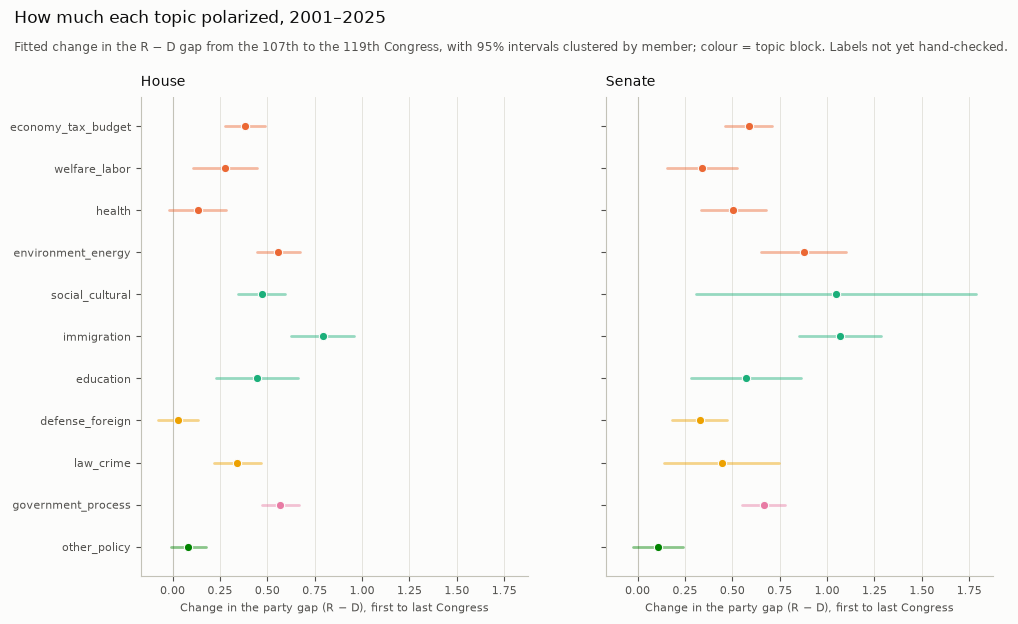

gap_2001                      change                        \
chamber                   H     S                     H                     S   
topic                                                                           
economy_tax_budget     0.76  0.66  +0.38 [+0.28, +0.49]  +0.59 [+0.46, +0.71]   
welfare_labor          0.72  0.68  +0.28 [+0.11, +0.45]  +0.34 [+0.16, +0.53]   
health                  0.8  0.73  +0.13 [-0.02, +0.28]  +0.51 [+0.33, +0.68]   
environment_energy     0.65  0.53  +0.56 [+0.44, +0.67]  +0.88 [+0.65, +1.10]   
social_cultural        1.06   0.5  +0.47 [+0.34, +0.59]  +1.04 [+0.31, +1.78]   
immigration            0.67  0.42  +0.79 [+0.63, +0.96]  +1.07 [+0.85, +1.29]   
education              0.51  0.56  +0.45 [+0.23, +0.66]  +0.57 [+0.28, +0.86]   
defense_foreign        0.49   0.4  +0.03 [-0.08, +0.13]  +0.33 [+0.18, +0.47]   
law_crime              0.41  0.29  +0.34 [+0.22, +0.47]  +0.44 [+0.14, +0.75]   
government_process     0.33  0.32  +0.57 [+0.47, +0.67]  +0.67 [+0.55, +0.78]   
other_policy           0.32  0.31  +0.08 [-0.01, +0.17]  +0.11 [-0.02, +0.24]   

                       n        
chamber                H     S  
topic                           
economy_tax_budget  8368  6329  
welfare_labor       1881  1107  
health              4259  3702  
environment_energy  4012  2564  
social_cultural     2203  1361  
immigration         1624  1423  
education           1066   727  
defense_foreign     6281  5015  
law_crime           1472  1075  
government_process  2820  4867  
other_policy        3009  1985

In [12]:
topic_order = [t for b in blocks for t in TOPIC_BLOCKS[b]]
block_color = dict(zip(blocks, TOPIC_BLOCK_PALETTE))
topic_trends = gap_trend(policy, by=("chamber", "topic"))
fig = plot_gap_trends(
    topic_trends, "topic",
    "How much each topic polarized, 2001–2025",
    subtitle="Fitted change in the R − D gap from the 107th to the 119th Congress, with 95% intervals clustered by member; colour = topic block. Labels not yet hand-checked.",
    order=topic_order,
    colors={t: block_color[BLOCK_OF_TOPIC[t]] for t in topic_order},
)
save_figure(fig, "overview_topic_polarization")
plt.show()

topic_trends.assign(gap_2001=topic_trends["gap_first"].round(2), change=span_ci(topic_trends),
                    p=topic_trends["p"].map(lambda p: f"{p:.2g}")).pivot(
    index="topic", columns="chamber", values=["gap_2001", "change", "n"]
).loc[topic_order]

**Reading it.** **Immigration polarized most in both chambers** (+0.79 House, +1.07
Senate over 2001–2025), followed by environment and energy (+0.56, +0.88),
social-cultural issues (+0.47, +1.04, the Senate's interval wide), government process
(+0.57, +0.67) and economy, tax and budget (+0.38, +0.59). **Defence and foreign
policy barely polarized in the House** (+0.03, interval includes 0) and modestly in
the Senate (+0.33); health in the House (+0.13) and the residual other_policy
(agriculture, transport, trade and the like) hardly at all. Topics also started from
different places: in 2001 the parties were furthest apart on social-cultural issues in
the House (1.06) and on health and the economy (0.66–0.80), closest on government
process (0.32–0.33), which then widened among the most. On these labels, the
polarization of 2001–2025 is concentrated in immigration, the environment,
social-cultural issues and how government itself works — not in foreign policy.

## 5. Age, generation and tenure

Each speaker's **birth year** comes from Voteview's member file (`born`; a year only,
so age is ±1) and their **tenure** — Congresses served so far, this one included, in
either chamber, back to 1789 — from the same file. Two measures of "polarizing":

- **extremity**: the ideology score in the party's own direction (Republicans as
  scored, Democrats sign-flipped), so higher means further toward the party's side;
- **tone**: hostility, as scored.

Both are compared **with the average of the speaker's own party, chamber and
Congress** (`relative_to_cell`), so a group difference is not the 2001–2025 trend in
disguise: 0.0 means "as extreme as their colleagues at the time".

**What cannot be separated:** within one Congress everyone's age is their birth year
seen from the same date, so an age difference and a generation difference are the
same thing. Age and tenure *can* be separated — members enter Congress at different
ages — so the last table estimates both at once.

Birth year known for 99.91% of speeches; speakers aged 26–100.
Median age of the speaker, per Congress and chamber:


congress_number,107,108,109,110,111,112,113,114,115,116,117,118,119
chamber,,,,,,,,,,,,,
H,56.0,57.0,58.0,58.0,60.0,61.0,61.0,61.0,63.0,61.0,62.0,62.0,61.0
S,60.0,62.0,63.0,65.0,66.0,66.0,65.0,66.0,67.0,69.0,69.0,71.0,71.0


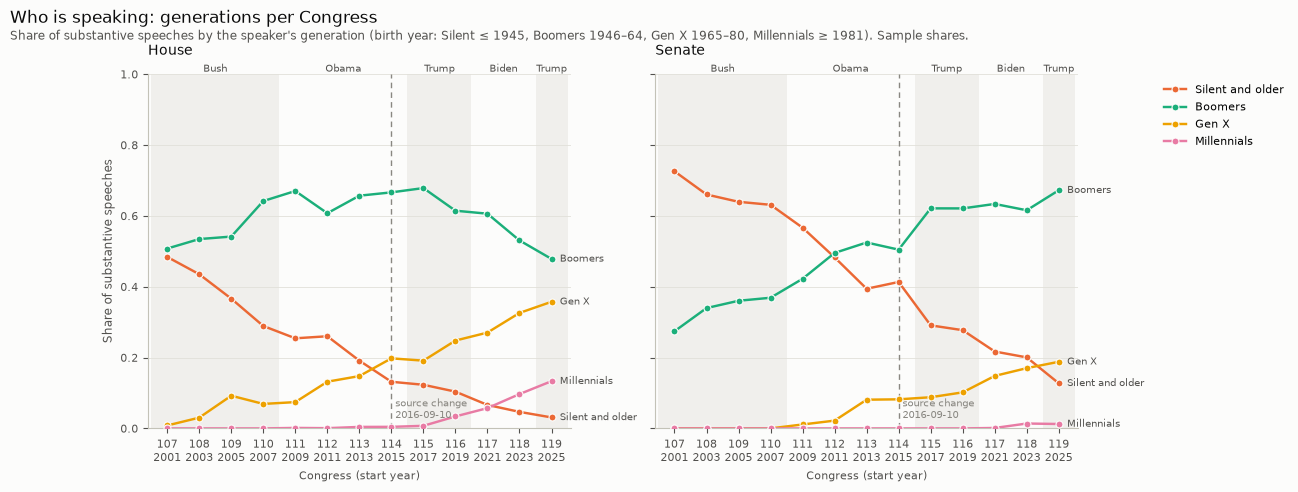

In [13]:
df = add_background(df, member_background())
df["extremity"] = toward_party(df)
df["extremity_vs_cell"] = relative_to_cell(df, "extremity")
df["tone_vs_cell"] = relative_to_cell(df, "tone")
df["age_decades"] = df["age"] / 10
print(f"Birth year known for {df['born'].notna().mean():.2%} of speeches; "
      f"speakers aged {df['age'].min():.0f}–{df['age'].max():.0f}.")
print("Median age of the speaker, per Congress and chamber:")
display(df.groupby(["congress_number", "chamber"])["age"].median().unstack("congress_number"))

generation_shares = label_shares(df, ["congress_number", "chamber"], column="generation")
fig = plot_label_shares(
    generation_shares, "Who is speaking: generations per Congress",
    subtitle="Share of substantive speeches by the speaker's generation (birth year: Silent ≤ 1945, Boomers 1946–64, Gen X 1965–80, Millennials ≥ 1981). Sample shares.",
    order=GENERATION_ORDER, column="generation", palette=TOPIC_BLOCK_PALETTE,
    ylabel="Share of substantive speeches",
)
save_figure(fig, "overview_generation_shares")
plt.show()

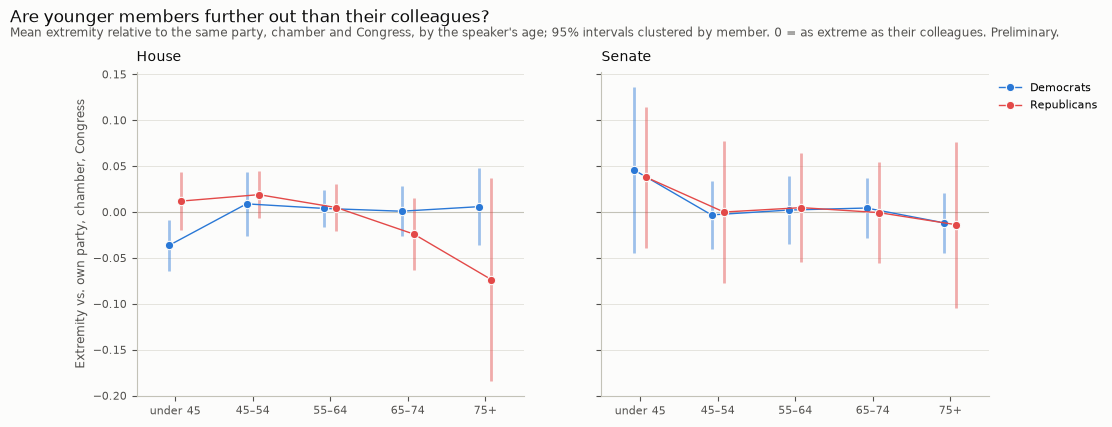

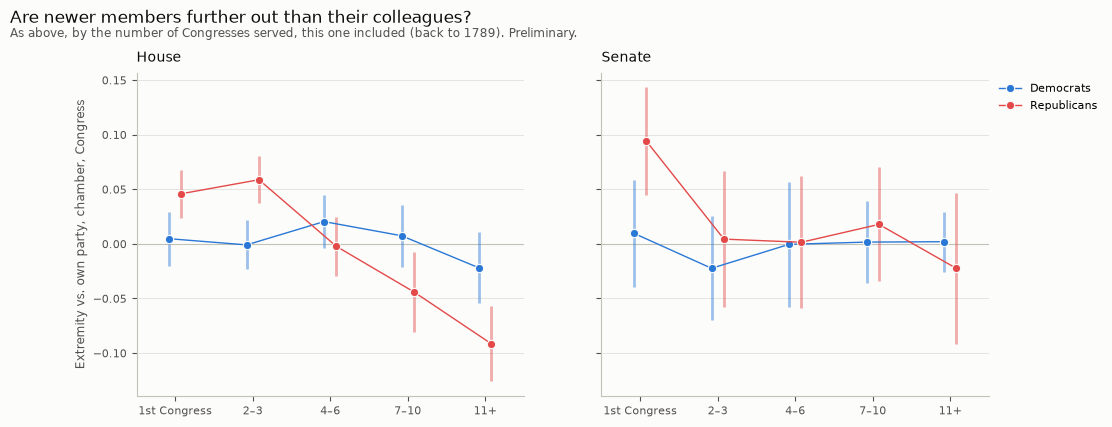

In [14]:
by_age = cell_means(df.dropna(subset=["age_group"]), "extremity_vs_cell", by=("chamber", "party", "age_group"))
fig = plot_group_means(
    by_age, "age_group",
    "Are younger members further out than their colleagues?",
    "Extremity vs. own party, chamber, Congress",
    subtitle="Mean extremity relative to the same party, chamber and Congress, by the speaker's age; 95% intervals clustered by member. 0 = as extreme as their colleagues. Preliminary.",
    order=AGE_GROUPS,
)
save_figure(fig, "overview_extremity_by_age")
plt.show()

by_tenure = cell_means(df.dropna(subset=["tenure_group"]), "extremity_vs_cell", by=("chamber", "party", "tenure_group"))
fig = plot_group_means(
    by_tenure, "tenure_group",
    "Are newer members further out than their colleagues?",
    "Extremity vs. own party, chamber, Congress",
    subtitle="As above, by the number of Congresses served, this one included (back to 1789). Preliminary.",
    order=TENURE_GROUPS,
)
save_figure(fig, "overview_extremity_by_tenure")
plt.show()

In [15]:
def table(frame, group, order, value):
    t = cell_means(frame.dropna(subset=[group]), value, by=("chamber", "party", group))
    t = t.assign(v=with_ci(t, digits=3), cell=t["chamber"] + " · " + t["party"])
    shown = t.pivot(index=group, columns="cell", values="v")
    members = t.pivot(index=group, columns="cell", values="n_members")
    present = [o for o in order if o in shown.index]
    return shown.loc[present], members.loc[present]

for group, order in (("age_group", AGE_GROUPS), ("generation", GENERATION_ORDER), ("tenure_group", TENURE_GROUPS)):
    for value in ("extremity_vs_cell", "tone_vs_cell"):
        shown, members = table(df, group, order, value)
        print(f"{value} by {group}:")
        display(shown)
    print(f"members per cell, by {group}:")
    display(members)

extremity_vs_cell by age_group:


cell,H · D,H · R,S · D,S · R
age_group,,,,
under 45,"-0.036 [-0.064, -0.009]","+0.012 [-0.020, +0.044]","+0.046 [-0.045, +0.136]","+0.038 [-0.040, +0.115]"
45–54,"+0.009 [-0.026, +0.044]","+0.019 [-0.007, +0.044]","-0.003 [-0.041, +0.034]","-0.000 [-0.078, +0.077]"
55–64,"+0.004 [-0.017, +0.024]","+0.005 [-0.021, +0.030]","+0.002 [-0.035, +0.039]","+0.005 [-0.054, +0.064]"
65–74,"+0.001 [-0.027, +0.028]","-0.024 [-0.064, +0.015]","+0.004 [-0.029, +0.037]","-0.001 [-0.056, +0.054]"
75+,"+0.006 [-0.036, +0.048]","-0.074 [-0.184, +0.036]","-0.012 [-0.045, +0.021]","-0.014 [-0.104, +0.076]"


tone_vs_cell by age_group:


cell,H · D,H · R,S · D,S · R
age_group,,,,
under 45,"-0.018 [-0.050, +0.014]","+0.003 [-0.021, +0.028]","-0.042 [-0.150, +0.065]","+0.054 [-0.006, +0.114]"
45–54,"+0.003 [-0.026, +0.032]","+0.009 [-0.011, +0.029]","-0.043 [-0.106, +0.020]","+0.010 [-0.017, +0.036]"
55–64,"-0.003 [-0.027, +0.021]","+0.001 [-0.022, +0.025]","+0.000 [-0.033, +0.034]","-0.009 [-0.047, +0.029]"
65–74,"-0.001 [-0.022, +0.020]","-0.006 [-0.038, +0.027]","+0.018 [-0.019, +0.054]","-0.003 [-0.046, +0.039]"
75+,"+0.026 [-0.007, +0.059]","-0.052 [-0.130, +0.027]","-0.010 [-0.074, +0.054]","+0.003 [-0.055, +0.062]"


members per cell, by age_group:


...

cell,H · D,H · R,S · D,S · R
tenure_group,,,,
1st Congress,"+0.005 [-0.020, +0.029]","+0.046 [+0.024, +0.068]","+0.010 [-0.040, +0.059]","+0.094 [+0.045, +0.143]"
2–3,"-0.001 [-0.023, +0.021]","+0.059 [+0.037, +0.080]","-0.022 [-0.070, +0.025]","+0.004 [-0.058, +0.067]"
4–6,"+0.020 [-0.004, +0.045]","-0.002 [-0.029, +0.025]","-0.000 [-0.058, +0.057]","+0.002 [-0.059, +0.062]"
7–10,"+0.007 [-0.021, +0.036]","-0.044 [-0.081, -0.007]","+0.002 [-0.036, +0.039]","+0.018 [-0.034, +0.070]"
11+,"-0.022 [-0.055, +0.011]","-0.092 [-0.126, -0.057]","+0.002 [-0.026, +0.030]","-0.022 [-0.091, +0.047]"


tone_vs_cell by tenure_group:


cell,H · D,H · R,S · D,S · R
tenure_group,,,,
1st Congress,"-0.033 [-0.055, -0.012]","+0.013 [-0.006, +0.031]","-0.059 [-0.097, -0.021]","+0.065 [+0.021, +0.109]"
2–3,"-0.015 [-0.035, +0.005]","+0.033 [+0.015, +0.052]","-0.073 [-0.144, -0.003]","+0.005 [-0.032, +0.043]"
4–6,"-0.008 [-0.031, +0.014]","-0.006 [-0.029, +0.017]","-0.006 [-0.059, +0.047]","+0.000 [-0.034, +0.034]"
7–10,"+0.013 [-0.014, +0.039]","-0.015 [-0.047, +0.017]","+0.015 [-0.014, +0.045]","-0.004 [-0.042, +0.033]"
11+,"+0.021 [-0.010, +0.051]","-0.042 [-0.077, -0.006]","+0.009 [-0.031, +0.049]","-0.005 [-0.056, +0.046]"


members per cell, by tenure_group:


cell,H · D,H · R,S · D,S · R
tenure_group,,,,
1st Congress,350,461,47,44
2–3,342,441,51,55
4–6,291,352,51,70
7–10,203,187,54,63
11+,120,79,46,42


In [16]:
age_tenure = pd.concat([
    within_cell_ols(df, value, ["age_decades", "tenure"], by=("chamber", "party")).assign(outcome=value)
    for value in ("extremity", "tone")
])
print("Age (per decade) and tenure (per Congress served) together, within party, chamber and Congress:")
age_tenure.assign(coef_ci=with_ci(age_tenure, "coef", digits=3), p=age_tenure["p"].map(lambda p: f"{p:.2g}"))[
    ["outcome", "chamber", "party", "term", "coef_ci", "p", "n", "n_members"]
].reset_index(drop=True)

Age (per decade) and tenure (per Congress served) together, within party, chamber and Congress:


,outcome,chamber,party,term,coef_ci,p,n,n_members
0,extremity,H,D,age_decades,"+0.021 [+0.002, +0.039]",0.029,19924,577
1,extremity,H,D,tenure,"-0.005 [-0.009, -0.001]",0.014,19924,577
2,extremity,H,R,age_decades,"+0.014 [-0.006, +0.034]",0.17,18251,688
3,extremity,H,R,tenure,"-0.015 [-0.019, -0.011]",1.1e-13,18251,688
4,extremity,S,D,age_decades,"-0.012 [-0.042, +0.018]",0.44,16792,123
5,extremity,S,D,tenure,"+0.002 [-0.003, +0.007]",0.44,16792,123
6,extremity,S,R,age_decades,"+0.014 [-0.031, +0.060]",0.54,16087,132
7,extremity,S,R,tenure,"-0.006 [-0.016, +0.004]",0.21,16087,132
8,tone,H,D,age_decades,"-0.010 [-0.028, +0.009]",0.31,19924,577
9,tone,H,D,tenure,"+0.005 [+0.001, +0.009]",0.013,19924,577


**Reading it.** **Who speaks changes a lot:** in the House the Silent generation falls
from 48% of substantive speeches (2001–2002) to 3% (2025) while Gen X rises to 36% and
Millennials to 13%; in the Senate the Silent generation falls from 72% to 13% and
Boomers take over. The Senate ages: median speaker 60 in 2001, 71 in 2025 (House 56 →
61–63).

**Younger is not further out.** Compared with their own party, chamber and Congress,
the age groups differ by at most about 0.05 in extremity, almost always within their
intervals. The one clear difference runs the other way: House Democrats under 45 are
slightly *less* far out (−0.036 [−0.064, −0.009]). Tone shows no age pattern. By
generation, Gen X senators sit further out than their colleagues (D +0.05, R +0.06),
but they are only 17 and 24 members.

**Newer is further out — for Republicans.** House Republicans in their first three
Congresses sit +0.05 to +0.06 to the right of their colleagues; those with 7–10 and
11+ Congresses −0.04 and −0.09. A newcomer–veteran difference of about 0.15 — close to
the House Republicans' whole 2001–2016 move (+0.20). Senate Republicans in their first
Congress are +0.09 [+0.05, +0.14]. With age held fixed, each Congress served makes a
House Republican 0.015 less far out (p < 10⁻¹²); for House Democrats the effect is a
third of that (−0.005), and at the same tenure older House Democrats are slightly
further out (+0.021 per decade). In tone, Republican newcomers are harsher than their
colleagues (House 2–3 Congresses +0.03, Senate first Congress +0.07) while Democratic
newcomers are milder (House −0.03, Senate −0.06). Senate estimates beyond that are too
uncertain to read.

This fits section 3: the parties, above all the Republicans, moved further than their
sitting members did, and the members who arrive later arrive further out. Two cautions:
members with long tenure are those who kept winning, and they hold leadership and
committee posts that change what they speak about — tenure is not only time.

**Saving the tables** to `results/metrics/` (committed).

In [17]:
tables = {
    "dropped_share": (dropped * 100).rename("dropped_pct").reset_index(),
    "party_gap": gaps,
    "gap_trends": gap_trends,
    "party_trends": party_trends,
    "member_trajectories": trajectories,
    "member_trends": movers,
    "gap_by_topic_block": block_gaps,
    "topic_block_shares": block_shares,
    "gap_trends_by_topic_block": block_trends,
    "gap_trends_by_topic": topic_trends,
    "generation_shares": generation_shares,
    "extremity_by_age": by_age,
    "extremity_by_tenure": by_tenure,
    "age_tenure_within_cell": age_tenure,
}
for name, table in tables.items():
    path = METRICS_DIR / f"overview_{name}_{RUN}.csv"
    table.to_csv(path, index=False)
    print(path.relative_to(ROOT))

results/metrics/overview_dropped_share_20261018T122536Z.csv
results/metrics/overview_party_gap_20261018T122536Z.csv


results/metrics/overview_gap_trends_20261018T122536Z.csv
results/metrics/overview_party_trends_20261018T122536Z.csv
results/metrics/overview_member_trajectories_20261018T122536Z.csv
results/metrics/overview_member_trends_20261018T122536Z.csv
results/metrics/overview_gap_by_topic_block_20261018T122536Z.csv
results/metrics/overview_topic_block_shares_20261018T122536Z.csv
results/metrics/overview_gap_trends_by_topic_block_20261018T122536Z.csv
results/metrics/overview_gap_trends_by_topic_20261018T122536Z.csv
results/metrics/overview_generation_shares_20261018T122536Z.csv
results/metrics/overview_extremity_by_age_20261018T122536Z.csv
results/metrics/overview_extremity_by_tenure_20261018T122536Z.csv
results/metrics/overview_age_tenure_within_cell_20261018T122536Z.csv


## 6. Caveats and open questions

- **Preliminary**, and resting on **labels not yet hand-checked** (L4): the
  exclusion and every topic result depend on them.
- **One model, a newer build than S8** (S18, S19): levels are not interchangeable with
  S8's; trends within this run are unaffected.
- **Unequal cells after the exclusion.** Every cell had 1,923 speeches; the Senate
  loses more to the exclusion than the House. Means are per cell, so this changes
  their precision, not their meaning.
- **Members:** followed only where they have ≥ 10 speeches in a Congress, so frequent
  speakers — senators, leaders — dominate; a member's own speeches are part of their
  party's mean, which shrinks `vs party` slightly. Replacement versus conversion is
  suggestive, not tested.
- **Arlen Specter's party is wrong in the Stanford data:** coded Democrat from the
  109th Congress (2005), though he switched only in April 2009. About 90 sampled
  speeches sit in the 109th–110th Senate Democratic cells (O13).
- **The 2016 source break** (O8): the 114th mixes both sources; 2001–2016 is the clean
  window.
- **Straight-line trends are summaries**, not claims that change was linear; positions
  also swing with the presidency.
- **Age:** a birth year only (±1 year); within a Congress age and generation cannot be
  told apart; long tenure means re-elected, so tenure groups are partly survivors;
  the Senate has 12–72 members per age group and party, too few for small
  differences.
- **Single topics are thin per Congress** (as few as 6 speeches in a party cell); they
  get one trend each, the blocks a line per Congress.